# Phase 2 — Ablation study (11)

Issue #69. Hybrid A (gated fusion, #64) combines several design choices. An *ablation* changes one of them at a time, keeps everything else at the chosen setting, and measures what the change costs or gains. The groups:

| Group | Variants | Question |
|---|---|---|
| window | 15, **30**, 60, 90 cycles | Does longer history help, and at which life stage? (the gap the project brief names) |
| cap | none, 100, **125**, 150 | How much does the training-label cap matter? |
| features | **all**, no age, current only, rolling only | Which engineered-feature groups (#57) does the feature branch need? |
| cycle | **off**, on | Does the cycle index help as an extra sequence input? |
| loss | **MSE**, asymmetric | Does a loss that charges late predictions more change accuracy? |
| branches | sequence only, features only, concatenation, **gated** | What does each branch, and the gate, add? |

Bold is the base setting (`configs/hybrid_gated.yaml`); it appears once in every group and is trained once. Every variant runs through `scripts/run_ablations.py` on the 3 Phase 1 engine folds (seed 42). The window and branches groups are also run at seeds 43 and 44, because they carry the main conclusions. The official test set is never used here.

**Terms used below**
- *Selection RMSE*: RMSE over held-out cycles whose true RUL is at most K = 130 (`selection.max_true_rul`, a placeholder until #55 fixes K). Every Phase 2 model is tuned on it.
- *Life stage*: the selection band split by true RUL: late ≤ 50 < mid ≤ 100 < early ≤ 130.
- *Engine error*: the RMSE over one held-out engine's cycles in the selection band. Each engine is held out exactly once, so every variant gives one error per engine and two variants can be compared engine by engine.
- *Asymmetric loss*: squared error with late predictions (more life predicted than is left) weighted (13/10)² ≈ 1.69, the ratio of the NASA score's second-order terms (`rul.training.trainer.AsymmetricMSELoss`).

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "scripts"))
import run_ablations as ra  # noqa: E402

from rul.data.load import load_subset
from rul.evaluation.metrics import STAGES, evaluate
from rul.evaluation.validation import holm_correction, paired_bootstrap_diff, paired_wilcoxon

CACHE = ROOT / "results/models/ablations"  # per-config cache (gitignored); delete it to retrain
METRICS = ROOT / "results/metrics"
FIGURES = ROOT / "results/figures"
FIGURES.mkdir(parents=True, exist_ok=True)

K = 130            # selection threshold on true RUL; every score below is computed from cached predictions with it
TRAINED_K = 130    # the threshold the cached runs were made with; it only affects scoring, so it is pinned
                   # to keep the cache keys when #55 changes dl_base.yaml (a new K then rescores, it doesn't retrain)
SEEDS = (42, 43, 44)
MULTI_SEED_GROUPS = ("window", "branches")

base, variants = ra.load_variants(ROOT / "configs/ablations.yaml")
base = ra.set_values(base, {"selection.max_true_rul": TRAINED_K})
train = load_subset(base["subset"], data_dir=ROOT / "data/raw/CMAPSSData").train
print(f"{len(variants)} variants in {len({v['group'] for v in variants})} groups, "
      f"{len({ra.config_key(ra.set_values(base, v['overrides'])) for v in variants})} distinct configs")

20 variants in 6 groups, 15 distinct configs


## 1. Run the grid

`run_ablations.main` cross-validates every variant at seed 42, or loads it from the cache, and rewrites `results/metrics/fd001_ablations.csv` (scored with `TRAINED_K`). The extra seeds for the window and branches groups go through the same `run_variant` (same cache), without touching that file.

In [2]:
summary = ra.main(["--set", f"selection.max_true_rul={TRAINED_K}"])

def load(entry: dict, seed: int) -> pd.DataFrame:
    # Held-out predictions for one variant at one training seed (trains it if not cached).
    config = ra.set_values(base, {**entry["overrides"], "training.seed": seed})
    _, predictions, _ = ra.run_variant(config, train, CACHE)
    return predictions

runs = {}
for entry in variants:
    seeds = SEEDS if entry["group"] in MULTI_SEED_GROUPS else SEEDS[:1]
    runs[entry["variant"]] = {seed: load(entry, seed) for seed in seeds}

[1/20] window_15: selection RMSE 16.65 ± 0.63 (cached)
[2/20] window_30: selection RMSE 16.81 ± 0.71 (cached)
[3/20] window_60: selection RMSE 16.76 ± 0.78 (cached)
[4/20] window_90: selection RMSE 16.80 ± 0.79 (cached)
[5/20] cap_none: selection RMSE 31.11 ± 1.71 (cached)
[6/20] cap_100: selection RMSE 15.68 ± 0.71 (cached)
[7/20] cap_125: selection RMSE 16.81 ± 0.71 (cached)
[8/20] cap_150: selection RMSE 19.96 ± 0.59 (cached)
[9/20] features_all: selection RMSE 16.81 ± 0.71 (cached)
[10/20] features_no_age: selection RMSE 17.50 ± 0.44 (cached)
[11/20] features_current_only: selection RMSE 16.27 ± 0.81 (cached)
[12/20] features_rolling_only: selection RMSE 17.35 ± 1.35 (cached)
[13/20] cycle_off: selection RMSE 16.81 ± 0.71 (cached)
[14/20] cycle_on: selection RMSE 16.28 ± 0.50 (cached)
[15/20] loss_mse: selection RMSE 16.81 ± 0.71 (cached)
[16/20] loss_asymmetric: selection RMSE 16.67 ± 0.55 (cached)
[17/20] branch_sequence: selection RMSE 15.78 ± 0.44 (cached)
[18/20] branch_featur

## 2. Summary table

One row per variant, at seed 42. `fold RMSE` is the selection RMSE of each fold, averaged over the 3 folds (± standard deviation); with K = 130 it equals the number in `fd001_ablations.csv`. The stage columns are computed over all held-out cycles in the selection band. `best epoch` is the median early-stopping epoch over folds.

In [3]:
DDOF = 1  # matches the fold spread run_cv reports

def band(pred: pd.DataFrame) -> pd.DataFrame:
    return pred[pred["rul"] <= K]

def stage_rmse(pred: pd.DataFrame) -> dict:
    by_stage = evaluate(band(pred)["rul"], band(pred)["prediction"])["by_stage"]
    return {stage: by_stage[stage]["rmse"] for stage in STAGES}

def engine_rmse(pred: pd.DataFrame) -> pd.Series:
    b = band(pred)
    return ((b["prediction"] - b["rul"]) ** 2).groupby(b["unit"]).mean() ** 0.5

def fold_rmse(pred: pd.DataFrame) -> pd.Series:
    b = band(pred)
    return ((b["prediction"] - b["rul"]) ** 2).groupby(b["fold"]).mean() ** 0.5

folds = pd.DataFrame({v: fold_rmse(r[42]) for v, r in runs.items()}).T
table = summary.set_index("variant")[["group", "median_best_epoch"]].rename(columns={"median_best_epoch": "best epoch"})
table.insert(1, "fold RMSE", folds.mean(axis=1))
table.insert(2, "± (folds)", folds.std(axis=1, ddof=DDOF))
stages = pd.DataFrame({v: stage_rmse(r[42]) for v, r in runs.items()}).T.add_suffix(" RMSE")
table = table.join(stages)
display(table.round(2))

,group,fold RMSE,± (folds),best epoch,early RMSE,mid RMSE,late RMSE
variant,,,,,,,
window_15,window,16.65,0.63,12,19.54,20.11,9.62
window_30,window,16.81,0.71,11,19.41,20.47,9.70
window_60,window,16.76,0.78,12,19.44,20.39,9.64
window_90,window,16.80,0.79,12,19.50,20.42,9.68
cap_none,cap,31.11,1.71,4,41.31,36.32,13.88
cap_100,cap,15.68,0.71,16,24.67,14.70,7.92
cap_125,cap,16.81,0.71,11,19.41,20.47,9.70
cap_150,cap,19.96,0.59,8,23.71,24.18,10.96
features_all,features,16.81,0.71,11,19.41,20.47,9.70


## 3. Which changes are real?

Each variant is compared with the base engine by engine (variant minus base; negative means the variant is better):

- a paired bootstrap 95% CI on the difference in RMSE over engines;
- a Wilcoxon signed-rank test on the engine errors, with Holm correction **once across all comparisons** (one family, so testing many variants does not inflate false positives).

For the window and branches groups both sides are averaged over seeds 42–44, so seed-to-seed variation is part of what the test sees. The other groups use seed 42 only. As in notebooks 09 and 12, the functions receive engine RMSEs against a target of zero, so "RMSE over engines" is the root mean square of the engine errors.

In [4]:
BASE = next(e["variant"] for e in variants if e["group"] == "branches" and not e["overrides"])
base_key = ra.config_key(ra.set_values(base, {}))

def engine_errors(variant: str, seeds) -> np.ndarray:
    return np.vstack([engine_rmse(runs[variant][s]).sort_index().to_numpy() for s in seeds])

rows, comparisons = [], {}
for entry in variants:
    name = entry["variant"]
    if ra.config_key(ra.set_values(base, entry["overrides"])) == base_key:
        continue  # the base setting itself
    seeds = tuple(runs[name])
    var, ref = engine_errors(name, seeds), engine_errors(BASE, seeds)
    zeros = np.zeros(var.shape[1])
    d = paired_bootstrap_diff(zeros, var, ref)
    comparisons[name] = (var, ref)
    rows.append({"variant": name, "group": entry["group"], "seeds": len(seeds),
                 "variant RMSE": np.sqrt((var**2).mean(axis=1)).mean(),
                 "base RMSE": np.sqrt((ref**2).mean(axis=1)).mean(),
                 "difference": d["difference"], "CI low": d["low"], "CI high": d["high"],
                 "engines better": int((var.mean(axis=0) < ref.mean(axis=0)).sum())})
tests = paired_wilcoxon(np.zeros(var.shape[1]), comparisons)
paired = pd.DataFrame(rows).set_index("variant")
paired["Holm p"] = [tests[v]["p_holm"] for v in paired.index]
paired.round(4).to_csv(METRICS / "fd001_ablations_paired.csv")
display(paired.round(3))

,group,seeds,variant RMSE,base RMSE,difference,CI low,CI high,engines better,Holm p
variant,,,,,,,,,
window_15,window,3,16.626,16.608,0.019,-0.173,0.211,47,1.000
window_60,window,3,16.681,16.608,0.073,-0.110,0.258,47,1.000
window_90,window,3,16.668,16.608,0.060,-0.115,0.232,44,1.000
cap_none,cap,1,31.144,16.821,14.323,11.255,17.363,17,0.000
cap_100,cap,1,15.694,16.821,-1.127,-2.327,0.052,43,1.000
cap_150,cap,1,19.975,16.821,3.154,1.909,4.372,28,0.000
features_no_age,features,1,17.504,16.821,0.683,-0.356,1.717,42,0.700
features_current_only,features,1,16.287,16.821,-0.533,-2.406,1.397,43,1.000
features_rolling_only,features,1,17.377,16.821,0.556,-0.496,1.561,45,1.000


### What the asymmetric loss changes

RMSE cannot show the loss's purpose, which is to move errors from late to early. The mean signed error (prediction minus truth; positive is late) and the NASA score (#56; lower is better, late errors cost more) over the selection band, seed 42:

In [5]:
loss_rows = []
for name in ("loss_mse", "loss_asymmetric"):
    b = band(runs[name][42])
    error = b["prediction"] - b["rul"]
    scores = evaluate(b["rul"], b["prediction"])
    loss_rows.append({"variant": name, "mean error": error.mean(), "share late": (error > 0).mean(),
                      "NASA score": scores["nasa_score"], "RMSE": scores["rmse"]})
display(pd.DataFrame(loss_rows).set_index("variant").round(3))

,mean error,share late,NASA score,RMSE
variant,,,,
loss_mse,0.621,0.516,127571.357,16.818
loss_asymmetric,-0.452,0.516,112268.292,16.676


## 4. Seeds for the window and branches groups

Mean and standard deviation over seeds 42–44 of the selection-band RMSE (all held-out cycles in the band), overall and by life stage.

In [6]:
seed_rows = []
for entry in variants:
    name = entry["variant"]
    if entry["group"] not in MULTI_SEED_GROUPS:
        continue
    scores = pd.DataFrame([{"selection": evaluate(band(p)["rul"], band(p)["prediction"])["rmse"], **stage_rmse(p)}
                           for p in runs[name].values()])
    seed_rows.append({"group": entry["group"], "variant": name,
                      **{f"{c} mean": scores[c].mean() for c in scores},
                      **{f"{c} std": scores[c].std(ddof=1) for c in scores}})
seed_table = pd.DataFrame(seed_rows).set_index("variant")
seed_table.round(3).to_csv(METRICS / "fd001_ablations_seeds.csv")
display(seed_table.round(2))

,group,selection mean,early mean,mid mean,late mean,selection std,early std,mid std,late std
variant,,,,,,,,,
window_15,window,16.62,19.48,20.07,9.58,0.12,0.27,0.25,0.33
window_30,window,16.60,19.39,20.06,9.62,0.24,0.30,0.48,0.34
window_60,window,16.68,19.54,20.22,9.44,0.09,0.11,0.16,0.24
window_90,window,16.66,19.48,20.20,9.48,0.13,0.29,0.25,0.19
branch_sequence,branches,16.90,15.88,21.69,11.09,0.98,1.13,0.78,1.43
branch_features,branches,17.40,20.08,21.29,9.79,0.23,0.28,0.34,0.37
branch_concat,branches,16.91,19.70,20.57,9.55,0.11,0.57,0.36,0.40
branch_gated,branches,16.60,19.39,20.06,9.62,0.24,0.30,0.48,0.34


## 5. Figure

Left: every variant's selection RMSE (seed 42, fold mean ± fold standard deviation), grouped, with the base as a dashed line. Right: stage-wise RMSE by window length, mean ± standard deviation over seeds 42–44.

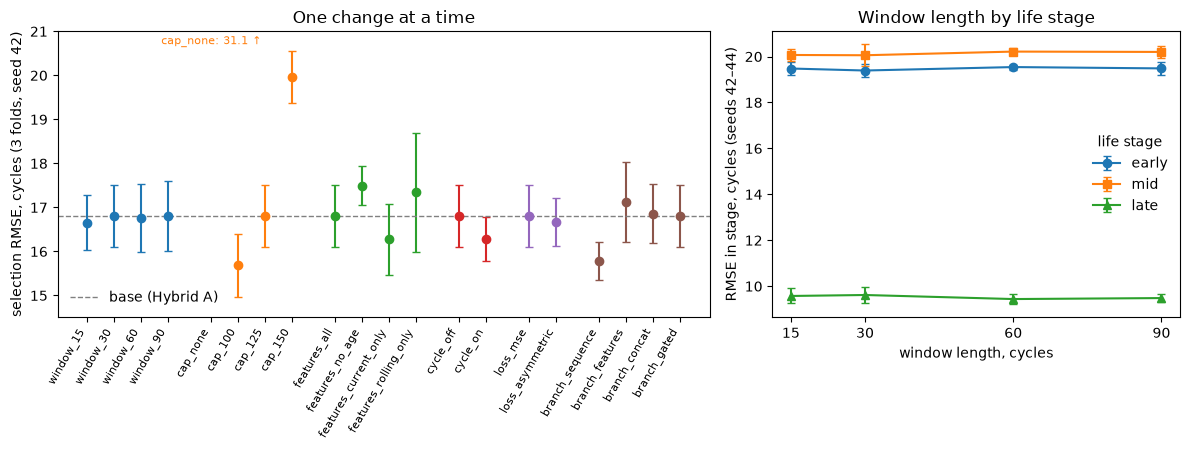

In [7]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})
groups = list(dict.fromkeys(e["group"] for e in variants))
colours = dict(zip(groups, plt.cm.tab10.colors))
x, ticks, TOP = 0, [], 21.0
for g in groups:
    for e in (e for e in variants if e["group"] == g):
        r = table.loc[e["variant"]]
        if r["fold RMSE"] > TOP:  # off the axis: label it instead of squashing the rest
            left.annotate(f"{e['variant']}: {r['fold RMSE']:.1f} ↑", (x, TOP - 0.1), ha="center", va="top",
                          fontsize=8, color=colours[g])
        else:
            left.errorbar(x, r["fold RMSE"], yerr=r["± (folds)"], fmt="o", color=colours[g], capsize=3)
        ticks.append((x, e["variant"]))
        x += 1
    x += 0.6
left.axhline(table.loc[BASE, "fold RMSE"], ls="--", color="grey", lw=1, label="base (Hybrid A)")
left.set_xticks([t for t, _ in ticks], [n for _, n in ticks], rotation=60, ha="right", fontsize=8)
left.set_ylim(14.5, TOP)
left.set_ylabel("selection RMSE, cycles (3 folds, seed 42)")
left.legend(frameon=False, loc="lower left")
left.set_title("One change at a time")

windows = [e for e in variants if e["group"] == "window"]
lengths = [e["overrides"].get("inputs.window", base["inputs"]["window"]) for e in windows]
for stage, marker in zip(STAGES, ("o", "s", "^")):
    means = [seed_table.loc[e["variant"], f"{stage} mean"] for e in windows]
    stds = [seed_table.loc[e["variant"], f"{stage} std"] for e in windows]
    right.errorbar(lengths, means, yerr=stds, marker=marker, capsize=3, label=stage)
right.set_xticks(lengths)
right.set_xlabel("window length, cycles")
right.set_ylabel("RMSE in stage, cycles (seeds 42–44)")
right.legend(title="life stage", frameon=False)
right.set_title("Window length by life stage")
fig.tight_layout()
fig.savefig(FIGURES / "fd001_ablations.png", dpi=150)
plt.show()

## 6. Findings

Differences are variant minus base in RMSE over engines (section 3); "not significant" means the 95% CI includes zero and the Holm-corrected p is above 0.05.

**Window length (3 seeds): longer history does not help Hybrid A on FD001.** Windows of 15, 60 and 90 cycles all land within 0.08 cycles of the 30-cycle base, with CIs inside ±0.26 and Holm p = 1. The right panel of the figure shows the same at every life stage: late-stage RMSE moves from 9.6 (30) to 9.4 (60), which is smaller than the seed spread. One reason is that the feature branch already summarizes the last 20 cycles, so extra raw history adds little the hybrid does not have. A second is that FD001 degradation is slow and smooth near the end of life, where most of the selection band sits. This answers the brief's question for this model and subset; it does not show that history never matters (FD004, with two fault modes, is a separate case not tested here).

**Branches (3 seeds): the gate is the most stable choice, not a clear accuracy win.**
- Features only is worse than the gated hybrid by 0.79. Its CI (0.41 to 1.18) excludes zero, but the Holm-corrected p is 0.051, so this is borderline: a hint that the sequence branch adds information, not proof.
- Sequence only is 0.29 worse on average (CI −1.49 to 2.19, not significant) but far less stable: its seed spread is 0.98 against 0.24 for the gate. At seed 42 alone it looked 1.0 better, which is why these two groups were rerun on three seeds. It is much better in the early stage (15.9 against 19.4) and worse in the late stage (11.1 against 9.6), so the gate trades early-stage accuracy for late-stage accuracy and consistency.
- Concatenation is 0.31 worse (CI −0.03 to 0.64, not significant). The gate's own gain over simply joining the branches is small.

**Cap (seed 42): 150 and no cap are clearly worse; 100 looks better but is not significant here.** No cap costs 14.3 cycles and 150 costs 3.2 (both Holm p < 0.001). A cap of 100 is 1.13 better (CI −2.33 to 0.05): it is more accurate in the mid and late stages (14.7 and 7.9 against 20.5 and 9.7) and worse early (24.7 against 19.4). This depends on K: a band of true RUL ≤ 130 contains few cycles where a cap of 100 is far off. The cap is chosen in #55, which is still open; this table should be read again once #55 fixes K.

**Feature groups (seed 42): no group changes the score significantly.** Current only (age plus current sensors) is 0.53 better, no age is 0.68 worse and rolling only is 0.56 worse, all with CIs that include zero. Combined with the window result, the hybrid does not depend on the rolling features: the sequence branch covers recent history already.

**Cycle input (seed 42): not significant** (−0.53, CI −1.52 to 0.51). The feature branch already receives `age`, so the cycle index is largely redundant in the hybrid.

**Asymmetric loss (seed 42): same RMSE, earlier predictions.** The RMSE change is −0.14 (not significant). The loss does what it is meant to: the mean signed error moves from +0.6 to −0.5 cycles and the NASA score over the band falls by 12%, while the share of late predictions stays at 52%. The shift comes from smaller late errors, not from fewer of them.

**What this means for the final model.** No variant beats the base setting with statistical support, so `configs/hybrid_gated.yaml` stays as it is for the freeze. The two choices worth carrying into the report are the cap (pending #55) and the asymmetric loss, if the team wants a lower NASA score at no RMSE cost.

**Limits.**
- The cap, features, cycle and loss groups use one training seed. Their differences under about 1 cycle are within the seed spread seen in the multi-seed groups (up to 0.98 for sequence only).
- Every variant changes one setting from the base; interactions (for example a longer window *with* sequence only) are not tested.
- K = 130 is a placeholder until #55. K is only used for scoring, so every table and the figure can be recomputed for a new K from the cached predictions: set `K` at the top and rerun. `fd001_ablations.csv` stays at K = 130.
- FD001 only. FD002/FD004 scaling is studied in notebook 12 (#70).